# ASL Citizen SLR — Green Computing, Model 3/5: Small ViViT (Transformer, Lightweight)

**Course:** CSE 407 — Green Computing
**Paper:** *Quantifying the Carbon Cost of Accuracy: An Energy-Aware Comparison of CNN and Transformer Architectures for Word-Level Sign Language Recognition*
**This notebook is 3 of 5** in the model family requested by faculty feedback on the proposal.

## Changelog / where this fits

### Relationship to notebooks 1-2 (CNN family)
This is the **first Transformer-family** entry (faculty suggestion 1's "small ViViT vs.
TimeSformer" pair) — the lightweight member, paired against notebook 4 (TimeSformer, heavy).
Sections 1-4 (cache, manifest, top-K filter, appearance-stream dataset) and Sections 7-11
(training loop, evaluation, green-computing accounting, model card export) are unchanged in
*shape* from notebooks 1-2 — same protocol, same constants — but **Section 5 is genuinely
different**, not a near-copy the way notebook 2 was of notebook 1. A CNN mean-pooled over time
and a real Transformer are different architecture families; that's the point of the comparison.

### What "small ViViT" means here
There's no official "ViViT-Small" checkpoint — Google's released ViViT sizes are Base/Large/
Huge. This notebook implements ViViT's own **Factorised Encoder** variant (Model 2 in
Arnab et al., *ViViT: A Video Vision Transformer*, ICCV 2021): a per-frame spatial Transformer
encoder, followed by a separate, shallow temporal Transformer encoder over the per-frame
embeddings. The spatial encoder is an ImageNet-pretrained **ViT-Tiny** (`vit_tiny_patch16_224`
via `timm`, ~5.7M params) — the smallest standard ViT backbone with public pretrained weights —
plus a small 2-layer temporal Transformer on top. That combination is what makes this the
*lightweight* Transformer-family member. **State this design choice explicitly in the paper's
methodology section** — "small ViViT" is a specific, documented interpretation here, not an
official model size.

### Two things that make this genuinely different from notebooks 1-2, not just relabeled
1. **Real temporal attention, not mean pooling.** The temporal encoder is an
   `nn.TransformerEncoder`, not `feats.mean(dim=1)` — this model can weight frames unevenly and
   model inter-frame relationships, which the CNN-family notebooks structurally cannot.
2. **FLOPs figure is a lower bound.** `thop`'s hooks count `nn.Conv2d`/`nn.Linear` FLOPs; the
   raw-tensor QK^T and attn@V matmuls inside attention aren't hooked, so Section 6's GFLOPs
   number under-counts this model specifically (flagged again inline and in the model card as
   `gflops_is_lower_bound: true`). This didn't matter for notebooks 1-2 (pure CNNs, where
   `Conv2d` hooks capture essentially all the compute) — it matters here. If RQ1's paper table
   needs a fair FLOPs comparison, note this caveat rather than presenting the numbers as
   directly comparable at face value.

### Reminders (same as notebooks 1-2)
1. **`CONFIG.TOP_K_CLASSES=100`, `GRID_CARBON_INTENSITY_KG_PER_KWH=0.475`,
   `EXPECTED_INFERENCE_VOLUME=100_000`** are unchanged from notebooks 1-2 — don't tune per-model.
2. **Not resumable across sessions** — a resumed run would restart `codecarbon` and undercount
   total training energy. Run start-to-finish in one session.
3. **Training hyperparameters (LR, batch size, epochs) are also unchanged** from notebooks 1-2
   on purpose, to preserve the controlled comparison. Transformers trained from a small
   pretrained ViT often want warmup or a lower LR than a CNN head — if training looks unstable
   here, that instability is itself a finding about this architecture family on this dataset
   scale, worth reporting rather than silently tuning away.
4. Scaffolding for the paper, not the paper — produces `green_metrics_vivit_lite_transformer_light.json`,
   matching notebooks 1-2's schema (plus the one added `gflops_is_lower_bound` field).

## 1. Setup & Imports

In [1]:
# --- One-time install of green-computing / profiling / model packages not preinstalled on Kaggle ---
import subprocess
import sys

for _pkg, _import_name in [("codecarbon", "codecarbon"), ("thop", "thop"), ("timm", "timm")]:
    try:
        __import__(_import_name)
    except ImportError:
        print(f"Installing {_pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import csv
import json
import math
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import precision_recall_fscore_support
import torchvision
import timm

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

print(f"Torch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"timm: {timm.__version__}")
print(f"Device: {DEVICE}")


Installing codecarbon ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.9/396.9 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 96.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 84.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 92.5 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sigstore 4.3.0 requires cryptography<49,>=42, but you have cryptography 50.0.0 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.0 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 50.0.0 which is incompatible.


Installing thop ...
Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
timm: 1.0.26
Device: cuda


## 1b. Hardware & Software Environment

Captured directly so energy/carbon figures in this notebook can be sanity-checked and reproduced (paper review Major Issue #4).

In [2]:
# --- Hardware / software environment capture (Green-Computing review fix #4) ---
# CodeCarbon's energy figures are software-based power *estimates*; a reader cannot judge
# their reliability, or reproduce this run, without knowing what hardware and software stack
# produced them. Captured once per run and carried into the model card / multi-seed report.
import platform

HARDWARE_INFO = {
    "torch_version": torch.__version__,
    "cuda_version_torch_built_with": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count_logical": __import__("os").cpu_count(),
    "gpu_available": torch.cuda.is_available(),
}

if torch.cuda.is_available():
    _gpu_props = torch.cuda.get_device_properties(0)
    HARDWARE_INFO.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "gpu_count": torch.cuda.device_count(),
        "gpu_total_memory_gb": round(_gpu_props.total_memory / (1024**3), 2),
        "gpu_capability": f"{_gpu_props.major}.{_gpu_props.minor}",
    })
else:
    HARDWARE_INFO.update({"gpu_name": None, "gpu_count": 0, "gpu_total_memory_gb": None, "gpu_capability": None})

# Best-effort CPU/RAM info via psutil if available (Kaggle usually has it); degrade gracefully.
try:
    import psutil
    HARDWARE_INFO["ram_total_gb"] = round(psutil.virtual_memory().total / (1024**3), 2)
except ImportError:
    HARDWARE_INFO["ram_total_gb"] = None

print("Hardware / software environment for this run:")
for k, v in HARDWARE_INFO.items():
    print(f"  {k}: {v}")
print()
print("NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity "
      "constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological "
      "assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is "
      "NOT necessarily the grid this specific session's hardware is physically attached to. "
      "If this notebook is run on infrastructure known to sit in a specific region, replace "
      "CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel "
      "reported CO2e figures accordingly -- see the paper review's Major Issue #5.")


Hardware / software environment for this run:
  torch_version: 2.10.0+cu128
  cuda_version_torch_built_with: 12.8
  cudnn_version: 91002
  python_version: 3.12.13
  platform: Linux-6.12.90+-x86_64-with-glibc2.35
  cpu_count_logical: 4
  gpu_available: True
  gpu_name: Tesla T4
  gpu_count: 2
  gpu_total_memory_gb: 14.56
  gpu_capability: 7.5
  ram_total_gb: 31.35

NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is NOT necessarily the grid this specific session's hardware is physically attached to. If this notebook is run on infrastructure known to sit in a specific region, replace CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel reported CO2e figures accordingly -- see the paper review's Major Issue #5.


## 2. Green-Computing & Model Configuration

In [3]:
class CONFIG:
    WORK_DIR = Path("/kaggle/working")

    # ---- update these to match your mounted paths -- identical to notebooks 1-2 ----
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")

    MODEL_TAG = "vivit_lite_transformer_light"
    CHECKPOINT_DIR = WORK_DIR / f"checkpoints_{MODEL_TAG}"
    OUTPUT_DIR = WORK_DIR / f"green_report_{MODEL_TAG}"

    # ---- Kept IDENTICAL to notebooks 1-2 -- see their Section 2 notes on why these
    # must not vary per-model. ----
    TOP_K_CLASSES = 100
    FRAME_COUNT = 16
    APPEARANCE_STREAM_IDX = 0
    IMAGE_SIZE = 224

    # ---- Model: "small ViViT", Transformer family, lighter member ----
    # There is no official "ViViT-Small" checkpoint (Google's released ViViT sizes are
    # Base/Large/Huge). This notebook implements ViViT's own "Factorised Encoder"
    # variant (Model 2 in Arnab et al. 2021: a per-frame spatial Transformer, then a
    # separate, shallow temporal Transformer over the per-frame embeddings) using an
    # ImageNet-pretrained ViT-Tiny (timm `vit_tiny_patch16_224`, ~5.7M params) as the
    # spatial encoder -- the smallest standard ViT backbone with public pretrained
    # weights, which is what makes this the *lightweight* Transformer-family member
    # paired against notebook 4's TimeSformer.
    SPATIAL_BACKBONE = "vit_tiny_patch16_224"
    # timm ViT-Tiny has 12 transformer blocks; freeze all but the last N (+ final norm),
    # same partial-freeze principle as notebooks 1-2's CNN backbones.
    SPATIAL_UNFROZEN_BLOCKS = 2

    # Temporal Transformer encoder (operates on the T per-frame embeddings from the
    # spatial encoder). Deliberately small/shallow -- this is the "light" Transformer
    # entry; notebook 4 (TimeSformer) is the heavy one.
    TEMPORAL_D_MODEL = 192          # matches ViT-Tiny's embed_dim -- no extra projection needed
    TEMPORAL_N_HEADS = 3
    TEMPORAL_N_LAYERS = 2
    TEMPORAL_FFN_DIM = 384
    TEMPORAL_DROPOUT = 0.3

    # ---- Training -- identical to notebooks 1-2. Transformers often want warmup / a
    # lower LR than CNNs, but changing this per-model would break the controlled
    # comparison the proposal's methodology calls for. If training is visibly unstable
    # (loss spikes/NaNs) with these settings, that instability is itself worth
    # reporting as a finding about this architecture family, not silently tuned away. ----
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    LR = 1e-4
    WEIGHT_DECAY = 3e-4
    GRAD_CLIP_NORM = 0.5
    LABEL_SMOOTHING = 0.1

    EPOCHS_FULL = 30
    MIN_EPOCHS_BEFORE_STOPPING = 15
    EARLY_STOPPING_PATIENCE = 6

    ACCURACY_GATE_THRESHOLD = 0.60  # soft reference point, not a hard requirement
    # The 60% figure above is author-chosen, not externally justified (paper review Minor
    # Issue #7). Rather than rest deployment conclusions on one unjustified line, the
    # deployment-readiness discussion (Section 10b) is reported parametrically across this
    # range so the reader can see whether the recommendation is threshold-sensitive.
    ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY = [0.50, 0.60, 0.70]

    SEED = 42
    # Repeated-seed runs for statistical validity (paper review Major Issue #2: every
    # comparative claim in the original single-run version rests on n=1 per model).
    # SEED remains the default/primary seed (used by the single detailed run in Sections
    # 7-9 with full training curves); SEEDS is the full set repeated in the new Section 9b
    # for mean +/- SD reporting. Kept short (3) so the added compute stays tractable --
    # extend if compute budget allows.
    SEEDS = [42, 123, 2024]
    DEVICE = DEVICE

    # ---- Green computing accounting -- identical constants to notebooks 1-2 ----
    GRID_CARBON_INTENSITY_KG_PER_KWH = 0.41272  # Google Cloud us-central1, 2024 (412.72 gCO2eq/kWh) -- see notebook 1, Section 2, for the full citation/caveat note
    EXPECTED_INFERENCE_VOLUME = 100_000

    # Sensitivity range for the lifecycle-carbon-per-inference metric (paper review
    # Recommended fix: the 100,000-inference figure is not sensitivity-tested in the
    # original submission). eta_life is reported at each of these volumes, not just the
    # single point assumption above, so the ranking in Section 10 can be checked for
    # stability across plausible deployment scales.
    DEPLOYMENT_VOLUME_SENSITIVITY = [10_000, 100_000, 1_000_000]
    INFERENCE_PROFILING_PASSES = 3


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG.SEED)
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Model tag: {CONFIG.MODEL_TAG}")
print(f"Device: {CONFIG.DEVICE}")
print(f"Top-K classes: {CONFIG.TOP_K_CLASSES}")


Model tag: vivit_lite_transformer_light
Device: cuda
Top-K classes: 100


## 3. Build the Manifest & Apply the Top-K Class Filter

In [4]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the Capstone notebooks' PILOT_MODE cell ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")


Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-100 filter applied -- NUM_CLASSES: 100
Videos remaining: 3200 across splits {'train': 1434, 'val': 357, 'test': 1409}
Videos/class (post-filter, all splits combined): min=32 median=32 max=32


### 3b. Signer-Independence Check

Verifies whether the pre-built train/val/test split is signer-disjoint (paper review Major Issue #1) before any model is trained on it.

In [5]:
# --- Signer-independence check for the train/val/test split (paper review Major Issue #1) ---
# ASL Citizen has 52 distinct signers. If the same signer appears in both train and test,
# accuracy is inflated by signer-specific visual cues (clothing, background, hand-shape
# idiosyncrasies) rather than sign semantics -- a leakage risk the original submission never
# checked. This cell re-reads the split CSVs looking for a participant/signer identifier and
# reports whether the pre-built splits in CONFIG.SPLITS_DIR are signer-disjoint.

POSSIBLE_SIGNER_COLUMNS = [
    "Participant ID", "ParticipantID", "Participant", "Signer ID", "SignerID",
    "Signer", "signer_id", "participant_id",
]

video_to_signer = {}
signer_column_used = None
for subset, csv_path in split_files.items():
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        fieldnames = reader.fieldnames or []
        if signer_column_used is None:
            signer_column_used = next((c for c in POSSIBLE_SIGNER_COLUMNS if c in fieldnames), None)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            if signer_column_used is not None:
                video_to_signer[video_id] = row[signer_column_used]
            else:
                # Fallback: ASL Citizen video filenames are prefixed with the participant ID
                # (e.g. "<participant_id>-<gloss>-<take>"). This is a heuristic, not a
                # guaranteed-correct parse -- flagged explicitly below.
                video_to_signer[video_id] = video_id.split("-")[0]

signers_by_subset = {s: set() for s in split_files}
for video_id, gloss, subset in rows:
    if video_id in video_to_signer:
        signers_by_subset[subset].add(video_to_signer[video_id])

overlap_train_val = signers_by_subset["train"] & signers_by_subset["val"]
overlap_train_test = signers_by_subset["train"] & signers_by_subset["test"]
overlap_val_test = signers_by_subset["val"] & signers_by_subset["test"]

SIGNER_INDEPENDENCE_REPORT = {
    "signer_column_found": signer_column_used,
    "signer_id_source": "csv_column" if signer_column_used is not None else "filename_prefix_heuristic",
    "n_signers_train": len(signers_by_subset["train"]),
    "n_signers_val": len(signers_by_subset["val"]),
    "n_signers_test": len(signers_by_subset["test"]),
    "n_signers_overlap_train_val": len(overlap_train_val),
    "n_signers_overlap_train_test": len(overlap_train_test),
    "n_signers_overlap_val_test": len(overlap_val_test),
    "is_signer_disjoint": (len(overlap_train_val) == 0 and len(overlap_train_test) == 0
                            and len(overlap_val_test) == 0),
}

print("Signer-independence check (paper review Major Issue #1):")
for k, v in SIGNER_INDEPENDENCE_REPORT.items():
    print(f"  {k}: {v}")

if signer_column_used is None:
    print("\n[WARNING] No explicit signer/participant column found in the split CSVs -- the "
          "signer IDs above were inferred from the video-filename prefix, which is a heuristic, "
          "NOT a verified signer identifier. Treat this report as provisional and confirm "
          "against ASL Citizen's official participant metadata before relying on it.")

if not SIGNER_INDEPENDENCE_REPORT["is_signer_disjoint"]:
    print("\n[MAJOR CAVEAT] Signer overlap detected across splits. Every accuracy figure in "
          "this notebook may be inflated by signer-specific cues rather than sign semantics. "
          "This should be disclosed alongside any accuracy number reported from this run, and "
          "a signer-disjoint re-split is required before the comparative claims in the paper "
          "can be trusted.")
else:
    print("\nSplits are signer-disjoint for every video where a signer ID could be resolved -- "
          "no cross-split signer leakage detected under this check.")


Signer-independence check (paper review Major Issue #1):
  signer_column_found: Participant ID
  signer_id_source: csv_column
  n_signers_train: 35
  n_signers_val: 5
  n_signers_test: 11
  n_signers_overlap_train_val: 0
  n_signers_overlap_train_test: 0
  n_signers_overlap_val_test: 0
  is_signer_disjoint: True

Splits are signer-disjoint for every video where a signer ID could be resolved -- no cross-split signer leakage detected under this check.


## 4. Dataset & DataLoaders — Appearance Stream

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def frames_to_tensor(frames_uint8):
    """(T, H, W, 3) uint8 -> (T, 3, IMAGE_SIZE, IMAGE_SIZE) float, ImageNet-normalized."""
    t = torch.from_numpy(frames_uint8).float() / 255.0        # (T, H, W, 3)
    t = t.permute(0, 3, 1, 2)                                  # (T, 3, H, W)
    t = F.interpolate(t, size=(CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE),
                       mode="bilinear", align_corners=False)
    t = (t - IMAGENET_MEAN) / IMAGENET_STD
    return t


class WLASLAppearanceDataset(Dataset):
    """Same cache, same manifest logic as the Capstone geometry-only notebook --
    this pulls the RGB appearance frames instead of the MediaPipe landmarks, since
    the CNN family (MobileNetV3 / ResNet-50) needs pixels, not landmark vectors."""

    def __init__(self, nslt_data, cache_index, subset):
        self.cache_index = cache_index
        self.samples = [
            (vid, meta["action"][0])
            for vid, meta in nslt_data.items()
            if meta["subset"] == subset and vid in self.cache_index
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_id, class_idx = self.samples[idx]
        data = np.load(self.cache_index[video_id])

        appearance_raw = data["appearance"]  # (T, num_streams, H, W, 3) uint8
        frames = appearance_raw[:, CONFIG.APPEARANCE_STREAM_IDX]  # (T, H, W, 3)
        frames_t = frames_to_tensor(frames)

        label = torch.tensor(class_idx, dtype=torch.long)
        return frames_t, label


train_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "train")
val_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "val")
test_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "test")

print(f"Train samples (cached): {len(train_dataset)}")
print(f"Val samples (cached):   {len(val_dataset)}")
print(f"Test samples (cached):  {len(test_dataset)}")

# --- WeightedRandomSampler for class imbalance -- unchanged from production ---
train_class_counts = Counter(class_idx for _, class_idx in train_dataset.samples)
train_sample_weights = [1.0 / train_class_counts[c] for _, c in train_dataset.samples]
train_sampler = WeightedRandomSampler(train_sample_weights, num_samples=len(train_sample_weights),
                                       replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG.BATCH_SIZE, sampler=train_sampler,
                           num_workers=CONFIG.NUM_WORKERS, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                         num_workers=CONFIG.NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                          num_workers=CONFIG.NUM_WORKERS)

sample_frames, sample_labels = next(iter(train_loader))
print("Batch frames shape:", sample_frames.shape)   # (B, T, 3, IMAGE_SIZE, IMAGE_SIZE)
print("Batch labels shape:", sample_labels.shape)


Train samples (cached): 1434
Val samples (cached):   357
Test samples (cached):  1409
Batch frames shape: torch.Size([8, 16, 3, 224, 224])
Batch labels shape: torch.Size([8])


## 5. Model Architecture — Small ViViT (Transformer, Lightweight, Factorised Encoder)

Per-frame ViT-Tiny spatial embeddings (ImageNet-pretrained, last `CONFIG.SPATIAL_UNFROZEN_BLOCKS`
blocks trainable) → temporal positional encoding → shallow temporal Transformer encoder →
mean-pooled → linear classification head. Genuinely Transformer-based end to end, unlike
notebooks 1-2's CNN-then-mean-pool models.

In [7]:
class ViTTinySpatialEncoder(nn.Module):
    """Per-frame spatial Transformer -- the first stage of ViViT's Factorised Encoder
    (Arnab et al. 2021, Model 2). ImageNet-pretrained ViT-Tiny, `num_classes=0` so it
    returns the pooled per-frame embedding directly instead of class logits."""

    def __init__(self, backbone_name=CONFIG.SPATIAL_BACKBONE, unfrozen_blocks=CONFIG.SPATIAL_UNFROZEN_BLOCKS):
        super().__init__()
        self.vit = timm.create_model(backbone_name, pretrained=True, num_classes=0)
        self.out_dim = self.vit.num_features  # 192 for vit_tiny_patch16_224

        # Freeze patch embedding + all but the last `unfrozen_blocks` transformer
        # blocks (+ final norm) -- same partial-freeze principle as notebooks 1-2's
        # CNN backbones, applied to ViT-Tiny's block list.
        for p in self.vit.parameters():
            p.requires_grad = False
        for block in self.vit.blocks[-unfrozen_blocks:]:
            for p in block.parameters():
                p.requires_grad = True
        for p in self.vit.norm.parameters():
            p.requires_grad = True

    def forward(self, x):
        # x: (B*T, 3, H, W) -> (B*T, out_dim)
        return self.vit(x)


class TemporalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=CONFIG.FRAME_COUNT):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class ViViTLiteFactorisedModel(nn.Module):
    """Transformer family, lightweight member: ViViT's Factorised Encoder variant --
    a per-frame ViT-Tiny spatial encoder, then a shallow temporal Transformer encoder
    over the T per-frame embeddings, then a linear classification head. Genuinely
    Transformer-based end to end (unlike notebooks 1-2's CNN-then-mean-pool models),
    which is the point of this half of the family comparison."""

    def __init__(self, num_classes):
        super().__init__()
        self.spatial_encoder = ViTTinySpatialEncoder()

        self.temporal_pos_encoding = TemporalPositionalEncoding(CONFIG.TEMPORAL_D_MODEL)
        temporal_layer = nn.TransformerEncoderLayer(
            d_model=CONFIG.TEMPORAL_D_MODEL, nhead=CONFIG.TEMPORAL_N_HEADS,
            dim_feedforward=CONFIG.TEMPORAL_FFN_DIM, dropout=CONFIG.TEMPORAL_DROPOUT,
            batch_first=True,
        )
        self.temporal_encoder = nn.TransformerEncoder(temporal_layer, num_layers=CONFIG.TEMPORAL_N_LAYERS)

        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(CONFIG.TEMPORAL_D_MODEL, num_classes)

    def forward(self, x):
        # x: (B, T, 3, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        per_frame_embed = self.spatial_encoder(x)              # (B*T, D)
        per_frame_embed = per_frame_embed.view(B, T, -1)        # (B, T, D)

        temporal_in = self.temporal_pos_encoding(per_frame_embed)
        temporal_out = self.temporal_encoder(temporal_in)       # (B, T, D)

        pooled = temporal_out.mean(dim=1)                        # (B, D)
        pooled = self.dropout(pooled)
        return self.head(pooled)


model = ViViTLiteFactorisedModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
n_params_total = sum(p.numel() for p in model.parameters())
n_params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params_total:,}")
print(f"Trainable parameters: {n_params_trainable:,}")


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

/tmp/ipykernel_23/1775697905.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.temporal_encoder = nn.TransformerEncoder(temporal_layer, num_layers=CONFIG.TEMPORAL_N_LAYERS)


Total parameters: 6,137,764
Trainable parameters: 1,503,460


## 6. Static Cost Profiling — Parameters & FLOPs

**Caveat for this model specifically:** the GFLOPs figure below is a lower bound — it excludes
attention matmuls not captured by `thop`'s module hooks. See the changelog above.

In [8]:
try:
    from thop import profile as thop_profile
    THOP_AVAILABLE = True
except ImportError:
    THOP_AVAILABLE = False
    print("[warning] thop not available -- FLOPs profiling skipped. "
          "`pip install thop` to enable it.")

# CAVEAT specific to this Transformer-family notebook: thop counts FLOPs via hooks on
# nn.Conv*/nn.Linear modules. Self-attention's QK^T and attn@V matmuls inside timm's
# and PyTorch's attention implementations are raw tensor ops, not nn.Linear calls, so
# thop does NOT count them. That means the GFLOPs figure below under-counts attention
# cost and is a LOWER BOUND, not a true total -- unlike notebooks 1-2 (pure CNNs),
# where thop's Conv2d hooks capture essentially all the compute. Flag this explicitly
# if using this number in the paper's RQ1 CNN-vs-Transformer FLOPs comparison.
if THOP_AVAILABLE:
    model.eval()
    dummy_input = torch.randn(1, CONFIG.FRAME_COUNT, 3, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE).to(CONFIG.DEVICE)
    macs, _thop_params = thop_profile(model, inputs=(dummy_input,), verbose=False)
    gflops_per_inference = (2 * macs) / 1e9  # MACs -> FLOPs; linear/conv layers only, see caveat above
    print(f"MACs per single-clip inference (linear/conv layers only): {macs:,.0f}")
    print(f"Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention matmuls): "
          f"{gflops_per_inference:.3f} GFLOPs")
else:
    gflops_per_inference = None


MACs per single-clip inference (linear/conv layers only): 17,199,336,192
Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention matmuls): 34.399 GFLOPs


In [9]:
try:
    from codecarbon import EmissionsTracker
    CODECARBON_AVAILABLE = True
    print("codecarbon available -- training/inference energy will be measured directly.")
except ImportError:
    CODECARBON_AVAILABLE = False
    print("[warning] codecarbon not available -- energy/carbon fields will be left as "
          "None throughout this notebook. `pip install codecarbon` to enable measurement; "
          "without it, this notebook still runs and reports accuracy/FLOPs/params, it just "
          "can't fill in the carbon-cost side of the paper's actual research question.")


codecarbon available -- training/inference energy will be measured directly.


## 7. Training Setup & Energy-Instrumented Training Run

Same per-epoch `codecarbon.EmissionsTracker` instrumentation as notebooks 1-2.

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)


def topk_accuracy(logits, labels, k=1):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    correct = topk.eq(labels.unsqueeze(1)).any(dim=1)
    return correct.float().mean().item()


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_top1, total_top5, n_batches = 0.0, 0.0, 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for frames, labels in loader:
            frames = frames.to(CONFIG.DEVICE)
            labels = labels.to(CONFIG.DEVICE)

            logits = model(frames)
            loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                print("  [warning] non-finite loss, batch skipped")
                continue

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP_NORM)
                optimizer.step()

            total_loss += loss.item()
            total_top1 += topk_accuracy(logits, labels, k=1)
            total_top5 += topk_accuracy(logits, labels, k=min(5, NUM_CLASSES))
            n_batches += 1

    return {
        "loss": total_loss / max(n_batches, 1),
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# --- Energy-instrumented training loop ---
# NOTE, deliberate difference from the Capstone notebooks: this run is NOT resumable
# across sessions. A resumed run would start a fresh CodeCarbon tracker and silently
# undercount total training energy -- and total training energy/carbon IS this
# notebook's actual research output, not a side effect to work around. Run it
# start-to-finish in one Kaggle session; if it gets interrupted, re-run from epoch 1
# rather than trusting a partial energy total.

history = []
best_val_top1 = -float("inf")
epochs_without_improvement = 0
best_state_dict = None
per_epoch_energy_kwh = []

BEST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "best_model.pt"

# Peak GPU memory during training (paper review Minor Issue #10: no memory metric was
# reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

t_start = time.time()
for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
    tracker = None
    if CODECARBON_AVAILABLE:
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_epoch{epoch}",
            output_dir=str(CONFIG.OUTPUT_DIR),
            log_level="error",
            save_to_file=False,
            allow_multiple_runs=True,
        )
        tracker.start()

    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    epoch_energy_kwh, epoch_co2_kg = None, None
    if tracker is not None:
        epoch_co2_kg = tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            epoch_energy_kwh = emissions_data.energy_consumed

    if epoch_energy_kwh is not None:
        per_epoch_energy_kwh.append(epoch_energy_kwh)
        energy_str = f"{epoch_energy_kwh:.5f} kWh"
    else:
        energy_str = "N/A"

    print(f"Epoch {epoch}/{CONFIG.EPOCHS_FULL} | "
          f"train_loss={train_metrics['loss']:.4f} train_top1={train_metrics['top1']:.3f} | "
          f"val_loss={val_metrics['loss']:.4f} val_top1={val_metrics['top1']:.3f} | "
          f"epoch_energy={energy_str}")

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "epoch_energy_kwh": epoch_energy_kwh,
        "epoch_co2_kg_codecarbon_estimate": epoch_co2_kg,
    })

    is_best = val_metrics["top1"] > best_val_top1
    if is_best:
        best_val_top1 = val_metrics["top1"]
        epochs_without_improvement = 0
        best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_top1": best_val_top1},
                    BEST_CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
            print(f"Early stopping at epoch {epoch} -- no val_top1 improvement for "
                  f"{CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
            break

wall_clock_train_minutes = (time.time() - t_start) / 60
print(f"\nTraining finished in {wall_clock_train_minutes:.1f} minutes. Best val_top1: {best_val_top1:.3f}")

PEAK_TRAIN_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
print(f"Peak GPU memory during training: {PEAK_TRAIN_GPU_MEMORY_GB} GB"
      if PEAK_TRAIN_GPU_MEMORY_GB is not None else "Peak GPU memory during training: N/A (no GPU)")

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
model.eval()

TOTAL_TRAIN_ENERGY_KWH = sum(per_epoch_energy_kwh) if per_epoch_energy_kwh else None
if TOTAL_TRAIN_ENERGY_KWH is not None:
    print(f"Total measured training energy ({len(per_epoch_energy_kwh)} epochs): "
          f"{TOTAL_TRAIN_ENERGY_KWH:.5f} kWh")
else:
    print("Total measured training energy: N/A (codecarbon not installed)")


[codecarbon WARNING @ 18:53:09] Multiple instances of codecarbon are allowed to run at the same time.


Epoch 1/30 | train_loss=4.7248 train_top1=0.018 | val_loss=4.6582 val_top1=0.013 | epoch_energy=0.00145 kWh
Epoch 2/30 | train_loss=4.6317 train_top1=0.017 | val_loss=4.6342 val_top1=0.011 | epoch_energy=0.00154 kWh
Epoch 3/30 | train_loss=4.4574 train_top1=0.032 | val_loss=4.5513 val_top1=0.035 | epoch_energy=0.00150 kWh
Epoch 4/30 | train_loss=4.2009 train_top1=0.084 | val_loss=4.4972 val_top1=0.038 | epoch_energy=0.00155 kWh
Epoch 5/30 | train_loss=4.0064 train_top1=0.105 | val_loss=4.4341 val_top1=0.059 | epoch_energy=0.00154 kWh
Epoch 6/30 | train_loss=3.7473 train_top1=0.177 | val_loss=4.3583 val_top1=0.062 | epoch_energy=0.00154 kWh
Epoch 7/30 | train_loss=3.5360 train_top1=0.248 | val_loss=4.3106 val_top1=0.078 | epoch_energy=0.00150 kWh
Epoch 8/30 | train_loss=3.3407 train_top1=0.308 | val_loss=4.3043 val_top1=0.070 | epoch_energy=0.00153 kWh
Epoch 9/30 | train_loss=3.1188 train_top1=0.379 | val_loss=4.2390 val_top1=0.078 | epoch_energy=0.00151 kWh
Epoch 10/30 | train_loss=2.9

## 8. Training Curves & Reference Accuracy Check

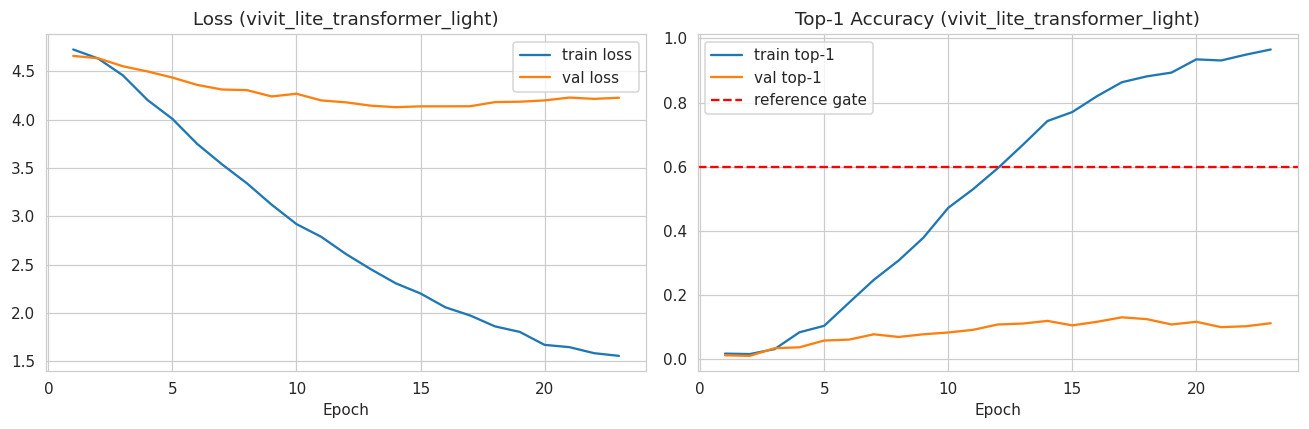

Best-checkpoint validation top-1: 0.131
Reference gate (0.60): not reached -- soft reference only, this notebook's primary output is the energy/carbon profile, not chasing this threshold


In [11]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss_curve = [h["val_loss"] for h in history]
train_top1 = [h["train_top1"] for h in history]
val_top1_curve = [h["val_top1"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, train_loss, label="train loss")
axes[0].plot(epochs_ran, val_loss_curve, label="val loss")
axes[0].set_title(f"Loss ({CONFIG.MODEL_TAG})"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, train_top1, label="train top-1")
axes[1].plot(epochs_ran, val_top1_curve, label="val top-1")
axes[1].axhline(CONFIG.ACCURACY_GATE_THRESHOLD, color="red", linestyle="--", label="reference gate")
axes[1].set_title(f"Top-1 Accuracy ({CONFIG.MODEL_TAG})"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG.OUTPUT_DIR / f"{CONFIG.MODEL_TAG}_train_val_curves.png", dpi=130, bbox_inches="tight")
plt.show()

best_epoch_val_top1 = best_val_top1
print(f"Best-checkpoint validation top-1: {best_epoch_val_top1:.3f}")
print(f"Reference gate ({CONFIG.ACCURACY_GATE_THRESHOLD:.2f}): "
      f"{'reached' if best_epoch_val_top1 >= CONFIG.ACCURACY_GATE_THRESHOLD else 'not reached'} "
      f"-- soft reference only, this notebook's primary output is the energy/carbon profile, "
      f"not chasing this threshold")


## 9. Test-Set Evaluation & Inference Energy Profiling

Same protocol as notebooks 1-2: one deterministic pass for accuracy, `CONFIG.INFERENCE_PROFILING_PASSES`
repeated passes for a stable energy-per-inference reading.

In [12]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_true, all_pred, all_top5 = [], [], []
    for frames, labels in loader:
        frames = frames.to(device)
        logits = model(frames)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        top1 = probs.argmax(axis=1)
        k = min(5, NUM_CLASSES)
        top5 = probs.argsort(axis=1)[:, ::-1][:, :k]
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(top1.tolist())
        all_top5.append(top5)
    return {
        "y_true": np.array(all_true),
        "y_pred": np.array(all_pred),
        "top5": np.concatenate(all_top5, axis=0),
    }


# --- Accuracy pass: single, deterministic, this is the number reported for accuracy ---
test_preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
test_top1 = (test_preds["y_true"] == test_preds["y_pred"]).mean()
test_top5 = np.mean([t in top5 for t, top5 in zip(test_preds["y_true"], test_preds["top5"])])
print(f"Test Top-1: {test_top1:.3f} | Test Top-5: {test_top5:.3f} | Test clips: {len(test_dataset)}")

_labels = list(range(NUM_CLASSES))
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="weighted", zero_division=0)
print(f"Macro F1: {macro_f1:.3f} | Weighted F1: {weighted_f1:.3f}")

# --- Energy-instrumented inference passes ---
# A single pass over a few hundred test clips is a short, noisy window for a
# power-sampling tracker like CodeCarbon. CONFIG.INFERENCE_PROFILING_PASSES repeats
# the full test-set pass to get a stabler average energy-per-inference reading.
# These repeated passes are NOT used for the accuracy numbers above (those stay a
# single deterministic pass) -- they exist purely to measure per-inference energy.
# Peak GPU memory and per-clip latency during inference (paper review Minor Issue #10:
# neither was reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

inference_energy_per_pass_kwh = []
inference_latency_seconds_per_pass = []
if CODECARBON_AVAILABLE:
    for pass_idx in range(CONFIG.INFERENCE_PROFILING_PASSES):
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_inference_pass{pass_idx}",
            output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
            save_to_file=False, allow_multiple_runs=True,
        )
        tracker.start()
        _pass_t0 = time.time()
        with torch.no_grad():
            for frames, _ in test_loader:
                frames = frames.to(CONFIG.DEVICE)
                _ = model(frames)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        inference_latency_seconds_per_pass.append(time.time() - _pass_t0)
        tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            inference_energy_per_pass_kwh.append(emissions_data.energy_consumed)

PEAK_INFERENCE_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
LATENCY_MS_PER_CLIP = (
    float(np.mean(inference_latency_seconds_per_pass)) / len(test_dataset) * 1000
    if inference_latency_seconds_per_pass else None
)
print(f"Peak GPU memory during inference: {PEAK_INFERENCE_GPU_MEMORY_GB} GB"
      if PEAK_INFERENCE_GPU_MEMORY_GB is not None else "Peak GPU memory during inference: N/A (no GPU)")
print(f"Mean latency per single-clip inference: {LATENCY_MS_PER_CLIP:.2f} ms"
      if LATENCY_MS_PER_CLIP is not None else "Mean latency per single-clip inference: N/A")

if inference_energy_per_pass_kwh:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = float(np.mean(inference_energy_per_pass_kwh))
    ENERGY_PER_CLIP_KWH = MEAN_INFERENCE_ENERGY_PER_PASS_KWH / len(test_dataset)
    print(f"\nMean energy per full test-set pass ({len(test_dataset)} clips): "
          f"{MEAN_INFERENCE_ENERGY_PER_PASS_KWH:.6f} kWh, across {len(inference_energy_per_pass_kwh)} passes")
    print(f"Estimated energy per single-clip inference: {ENERGY_PER_CLIP_KWH * 1e6:.2f} mWh")
else:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = None
    ENERGY_PER_CLIP_KWH = None
    print("\nInference energy profiling skipped (codecarbon not installed).")


Test Top-1: 0.116 | Test Top-5: 0.345 | Test clips: 1409
Macro F1: 0.100 | Weighted F1: 0.101
Peak GPU memory during inference: 0.354 GB
Mean latency per single-clip inference: 24.18 ms

Mean energy per full test-set pass (1409 clips): 0.000951 kWh, across 3 passes
Estimated energy per single-clip inference: 0.67 mWh


### 9b. External Accuracy Reference Points (Not Reproduced Locally)

**Paper review Major Issue #3:** this study only compares its own five models against each
other. Without an external reference point, a reader cannot tell whether this notebook's
top-1 accuracy on the 100-class ASL Citizen pilot is competitive, mediocre, or unusually low
for the task -- the accuracy ceiling could reflect task difficulty at this scale just as
easily as an architectural or protocol limitation.

We do **not** reproduce these external numbers in this notebook (different class subsets,
splits, and training budgets make a like-for-like re-run out of scope for a single-model
green-computing unit), but they are recorded here so the number produced above can be read
in context rather than in isolation:

- **Alkhoraif et al. (2026)** report state-of-the-art accuracy on ASL Citizen (among other
  datasets) using a two-stream Swin-Transformer ensemble combining appearance and pose
  modalities -- a substantially heavier, multi-modal pipeline than any single model in this
  family.
- **Brettmann et al. (2025)** report that a VideoMAE-based ViViT variant substantially
  outperforms a traditional CNN baseline on WLASL100, a comparable-scale (100-class)
  word-level sign recognition benchmark.
- **Shawon et al. (2026)** compare VideoMAE, ViViT, and TimeSformer -- the same TimeSformer
  family used as this study's heavy Transformer entry -- on Bangla Sign Language datasets,
  finding video-Transformer accuracy sensitive to dataset size, frame rate, and signer
  variation.

None of these three report training or inference energy alongside their accuracy figures,
which is precisely the gap this five-model family's green-computing instrumentation exists
to fill -- but their accuracy numbers are the closest available external reference for
judging whether this notebook's own top-1 figure is in a reasonable range for a 100-class
word-level sign recognition task. A future revision could re-run one of these external
methods on this exact 100-class split to make the comparison direct rather than contextual.

## 10. Green-Computing Accounting — Carbon, Amortization, Efficiency

Same Eq. (1) / Eq. (2) / amortized-carbon math as notebooks 1-2, same constants — required for
this notebook's numbers to be comparable against the CNN family.

In [13]:
def fmt(value, spec=".4f", suffix=""):
    return "N/A" if value is None else f"{value:{spec}}{suffix}"


GRID_INTENSITY = CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH  # kg CO2e / kWh -- Eq. (1) in the proposal


def kwh_to_co2_kg(kwh):
    return None if kwh is None else kwh * GRID_INTENSITY


# --- Eq. (1): energy -> carbon ---
train_co2_kg_estimated = kwh_to_co2_kg(TOTAL_TRAIN_ENERGY_KWH)
inference_co2_kg_per_clip = kwh_to_co2_kg(ENERGY_PER_CLIP_KWH)

train_co2_g = None if train_co2_kg_estimated is None else train_co2_kg_estimated * 1000
inference_co2_mg_per_clip = None if inference_co2_kg_per_clip is None else inference_co2_kg_per_clip * 1e6

print("[Eq. 1] Estimated total training CO2e:", fmt(train_co2_g, ".2f", " g"),
      f"(grid intensity assumption: {GRID_INTENSITY} kg/kWh)")
print("[Eq. 1] Estimated CO2e per inference:", fmt(inference_co2_mg_per_clip, ".3f", " mg"))

# --- Faculty feedback: amortized training carbon / expected inference volume ---
# CONFIG.EXPECTED_INFERENCE_VOLUME is a placeholder deployment-scenario assumption
# (see CONFIG comment) -- swap in a properly justified/cited figure before this goes
# in the paper.
amortized_training_co2_per_inference_kg = None
if train_co2_kg_estimated is not None:
    amortized_training_co2_per_inference_kg = train_co2_kg_estimated / CONFIG.EXPECTED_INFERENCE_VOLUME

total_lifecycle_co2_per_inference_kg = None
if amortized_training_co2_per_inference_kg is not None and inference_co2_kg_per_clip is not None:
    total_lifecycle_co2_per_inference_kg = (
        amortized_training_co2_per_inference_kg + inference_co2_kg_per_clip
    )

amortized_mg = None if amortized_training_co2_per_inference_kg is None else amortized_training_co2_per_inference_kg * 1e6
lifecycle_mg = None if total_lifecycle_co2_per_inference_kg is None else total_lifecycle_co2_per_inference_kg * 1e6

print(f"\nAmortized training CO2e per inference "
      f"(assuming {CONFIG.EXPECTED_INFERENCE_VOLUME:,} lifetime inferences):", fmt(amortized_mg, ".4f", " mg"))
print("Total lifecycle CO2e per inference (amortized training + marginal inference):",
      fmt(lifecycle_mg, ".4f", " mg"))

# --- Eq. (2): accuracy-per-carbon efficiency metric ---
def efficiency_metric(accuracy_pct, co2_g):
    if co2_g is None or co2_g == 0:
        return None
    return accuracy_pct / co2_g


eta_train = efficiency_metric(test_top1 * 100, train_co2_g)
lifecycle_co2_g_per_inference = None if lifecycle_mg is None else lifecycle_mg / 1000
eta_lifecycle_per_inference = efficiency_metric(test_top1 * 100, lifecycle_co2_g_per_inference)

print("\n[Eq. 2] eta_acc/carbon (training-total basis):", fmt(eta_train, ".4f", " % per g CO2e"))
print("[Eq. 2] eta_acc/carbon (per-inference lifecycle basis):",
      fmt(eta_lifecycle_per_inference, ".6f", " % per g CO2e"))

# --- Lifecycle sensitivity analysis (paper review Recommended fix: the single 100,000-
# inference deployment-volume assumption was never sensitivity-tested in the original
# submission). Recomputes eta_life at each volume in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY
# so the model's efficiency ranking can be checked for stability across plausible scales,
# not just trusted at one arbitrary point estimate.
lifecycle_sensitivity = []
for n_inf in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY:
    amortized_kg_n = None if train_co2_kg_estimated is None else train_co2_kg_estimated / n_inf
    lifecycle_kg_n = None
    if amortized_kg_n is not None and inference_co2_kg_per_clip is not None:
        lifecycle_kg_n = amortized_kg_n + inference_co2_kg_per_clip
    lifecycle_g_n = None if lifecycle_kg_n is None else lifecycle_kg_n * 1000
    eta_life_n = efficiency_metric(test_top1 * 100, lifecycle_g_n)
    lifecycle_sensitivity.append({
        "deployment_volume_inferences": n_inf,
        "lifecycle_co2_mg_per_inference": None if lifecycle_kg_n is None else lifecycle_kg_n * 1e6,
        "eta_lifecycle_pct_per_g_co2e": eta_life_n,
    })

print("\n[Sensitivity] eta_life across deployment-volume assumptions (not just the single",
      f"{CONFIG.EXPECTED_INFERENCE_VOLUME:,}-inference point estimate):")
for row in lifecycle_sensitivity:
    print(f"  N={row['deployment_volume_inferences']:>10,}  "
          f"lifecycle_CO2e/inference={fmt(row['lifecycle_co2_mg_per_inference'], '.4f', ' mg')}  "
          f"eta_life={fmt(row['eta_lifecycle_pct_per_g_co2e'], '.6f', ' %/g CO2e')}")

# --- Parametric deployment-threshold check (paper review Minor Issue #7: the 60% soft
# accuracy reference is author-defined, not externally justified). Reports whether this
# model clears each candidate threshold rather than resting the deployment narrative on
# one unjustified line.
threshold_check = {
    f"clears_{int(t*100)}pct_threshold": bool(test_top1 >= t)
    for t in CONFIG.ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY
}
print("\n[Sensitivity] Deployment-threshold check (test_top1 =", f"{test_top1:.3f}):")
for k, v in threshold_check.items():
    print(f"  {k}: {v}")


[Eq. 1] Estimated total training CO2e: 14.32 g (grid intensity assumption: 0.41272 kg/kWh)
[Eq. 1] Estimated CO2e per inference: 0.279 mg

Amortized training CO2e per inference (assuming 100,000 lifetime inferences): 0.1432 mg
Total lifecycle CO2e per inference (amortized training + marginal inference): 0.4217 mg

[Eq. 2] eta_acc/carbon (training-total basis): 0.8078 % per g CO2e
[Eq. 2] eta_acc/carbon (per-inference lifecycle basis): 27430.519819 % per g CO2e

[Sensitivity] eta_life across deployment-volume assumptions (not just the single 100,000-inference point estimate):
  N=    10,000  lifecycle_CO2e/inference=1.7106 mg  eta_life=6762.928504 %/g CO2e
  N=   100,000  lifecycle_CO2e/inference=0.4217 mg  eta_life=27430.519819 %/g CO2e
  N= 1,000,000  lifecycle_CO2e/inference=0.2929 mg  eta_life=39502.545512 %/g CO2e

[Sensitivity] Deployment-threshold check (test_top1 = 0.116):
  clears_50pct_threshold: False
  clears_60pct_threshold: False
  clears_70pct_threshold: False


## 10b. Multi-Seed Repetition for Statistical Validity

Repeats the full train+eval pipeline across `CONFIG.SEEDS` and reports mean +/- SD for every headline metric (paper review Major Issue #2). This is the single most compute-expensive addition in this notebook -- it multiplies total training cost by `len(CONFIG.SEEDS)`, which is itself worth reporting as part of this study's own carbon cost of doing rigorous science.

In [14]:
# --- Multi-seed repetition for statistical validity (paper review Major Issue #2: every
# comparative claim in the original single-run submission rested on n=1 per model, with
# no seeds, no variance, no CI anywhere -- self-disclosed but never fixed). The seed
# CONFIG.SEED run above (Sections 7-9) is reused as the first data point; this cell repeats
# the full train+eval pipeline for every remaining seed in CONFIG.SEEDS and reports
# mean +/- SD for every headline metric, so the model-vs-model rankings in the cross-model
# comparison can finally be checked against run-to-run noise.

MULTI_SEED_RESULTS = [{
    "seed": CONFIG.SEED,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "total_train_co2_g": train_co2_g,
    "eta_acc_per_carbon_training_basis": eta_train,
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
}]


def _train_and_evaluate_one_seed(seed):
    """Rebuilds the model from scratch under a fresh seed, retrains it end-to-end with
    the same protocol as the primary run (Section 7), evaluates it, and returns the same
    headline metrics as the primary run's globals -- so it can be folded into
    MULTI_SEED_RESULTS on equal footing."""
    global model, optimizer, scheduler

    seed_everything(seed)
    model = ViViTLiteFactorisedModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)

    _best_val_top1 = -float("inf")
    _epochs_without_improvement = 0
    _best_state_dict = None
    _per_epoch_energy_kwh = []
    _epochs_ran = 0

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

    _t0 = time.time()
    for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
        tracker = None
        if CODECARBON_AVAILABLE:
            tracker = EmissionsTracker(
                project_name=f"{CONFIG.MODEL_TAG}_seed{seed}_epoch{epoch}",
                output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
                save_to_file=False, allow_multiple_runs=True,
            )
            tracker.start()

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)
        scheduler.step()
        _epochs_ran = epoch

        epoch_energy_kwh = None
        if tracker is not None:
            tracker.stop()
            emissions_data = tracker.final_emissions_data
            if emissions_data is not None:
                epoch_energy_kwh = emissions_data.energy_consumed
        if epoch_energy_kwh is not None:
            _per_epoch_energy_kwh.append(epoch_energy_kwh)

        is_best = val_metrics["top1"] > _best_val_top1
        if is_best:
            _best_val_top1 = val_metrics["top1"]
            _epochs_without_improvement = 0
            _best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            _epochs_without_improvement += 1
            if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                    and _epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
                print(f"  [seed {seed}] early stopping at epoch {epoch}")
                break

    wall_min = (time.time() - _t0) / 60
    if _best_state_dict is not None:
        model.load_state_dict(_best_state_dict)
    model.eval()

    peak_train_mem_gb = (
        round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
        if torch.cuda.is_available() else None
    )
    total_train_energy_kwh = sum(_per_epoch_energy_kwh) if _per_epoch_energy_kwh else None

    preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
    seed_test_top1 = float((preds["y_true"] == preds["y_pred"]).mean())
    seed_test_top5 = float(np.mean([t in top5 for t, top5 in zip(preds["y_true"], preds["top5"])]))

    train_co2_kg_seed = kwh_to_co2_kg(total_train_energy_kwh)
    train_co2_g_seed = None if train_co2_kg_seed is None else train_co2_kg_seed * 1000
    eta_train_seed = efficiency_metric(seed_test_top1 * 100, train_co2_g_seed)

    print(f"  [seed {seed}] test_top1={seed_test_top1:.3f} epochs={_epochs_ran} "
          f"train_co2_g={fmt(train_co2_g_seed, '.2f')} wall_min={wall_min:.1f}")

    return {
        "seed": seed,
        "test_top1": seed_test_top1,
        "test_top5": seed_test_top5,
        "best_val_top1": float(_best_val_top1),
        "epochs_ran": _epochs_ran,
        "total_train_energy_kwh": total_train_energy_kwh,
        "total_train_co2_g": train_co2_g_seed,
        "eta_acc_per_carbon_training_basis": eta_train_seed,
        "wall_clock_train_minutes": wall_min,
        "peak_train_gpu_memory_gb": peak_train_mem_gb,
    }


for _seed in CONFIG.SEEDS:
    if _seed == CONFIG.SEED:
        continue
    print(f"\n=== Repeating full train+eval for seed={_seed} ===")
    MULTI_SEED_RESULTS.append(_train_and_evaluate_one_seed(_seed))

# --- Aggregate mean +/- SD across all collected seeds ---
import statistics as _stats


def _mean_sd(metric_key):
    vals = [r[metric_key] for r in MULTI_SEED_RESULTS if r.get(metric_key) is not None]
    if not vals:
        return None, None
    if len(vals) == 1:
        return vals[0], 0.0
    return _stats.mean(vals), _stats.stdev(vals)


MULTI_SEED_SUMMARY = {"n_seeds": len(MULTI_SEED_RESULTS), "seeds": [r["seed"] for r in MULTI_SEED_RESULTS]}
for _k in ["test_top1", "test_top5", "total_train_co2_g", "eta_acc_per_carbon_training_basis",
           "total_train_energy_kwh", "wall_clock_train_minutes"]:
    _m, _s = _mean_sd(_k)
    MULTI_SEED_SUMMARY[f"{_k}_mean"] = _m
    MULTI_SEED_SUMMARY[f"{_k}_std"] = _s

print(f"\n=== Multi-seed summary (n={MULTI_SEED_SUMMARY['n_seeds']} seeds: {MULTI_SEED_SUMMARY['seeds']}) ===")
for _k, _v in MULTI_SEED_SUMMARY.items():
    if _k in ("n_seeds", "seeds"):
        continue
    print(f"  {_k}: {fmt(_v, '.4f')}")



=== Repeating full train+eval for seed=123 ===


/tmp/ipykernel_23/1775697905.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.temporal_encoder = nn.TransformerEncoder(temporal_layer, num_layers=CONFIG.TEMPORAL_N_LAYERS)


  [seed 123] early stopping at epoch 18
  [seed 123] test_top1=0.081 epochs=18 train_co2_g=11.17 wall_min=17.3

=== Repeating full train+eval for seed=2024 ===


/tmp/ipykernel_23/1775697905.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.temporal_encoder = nn.TransformerEncoder(temporal_layer, num_layers=CONFIG.TEMPORAL_N_LAYERS)


  [seed 2024] early stopping at epoch 17
  [seed 2024] test_top1=0.085 epochs=17 train_co2_g=10.53 wall_min=16.3

=== Multi-seed summary (n=3 seeds: [42, 123, 2024]) ===
  test_top1_mean: 0.0939
  test_top1_std: 0.0190
  test_top5_mean: 0.2907
  test_top5_std: 0.0517
  total_train_co2_g_mean: 12.0051
  total_train_co2_g_std: 2.0307
  eta_acc_per_carbon_training_basis_mean: 0.7804
  eta_acc_per_carbon_training_basis_std: 0.0485
  total_train_energy_kwh_mean: 0.0291
  total_train_energy_kwh_std: 0.0049
  wall_clock_train_minutes_mean: 18.5959
  wall_clock_train_minutes_std: 3.1390


## 11. Model Card Export

Saves `green_metrics_vivit_lite_transformer_light.json`, matching notebooks 1-2's schema (with
one added field, `gflops_is_lower_bound`, flagging the Section 6 caveat).

In [15]:
model_card = {
    "model_tag": CONFIG.MODEL_TAG,
    "architecture_family": "Transformer (lightweight, ViViT Factorised Encoder)",
    "backbone": "ViT-Tiny spatial encoder (ImageNet-pretrained) + 2-layer temporal Transformer",
    "num_classes": NUM_CLASSES,
    "top_k_classes_config": CONFIG.TOP_K_CLASSES,
    "frame_count": CONFIG.FRAME_COUNT,
    "image_size": CONFIG.IMAGE_SIZE,
    "params_total": n_params_total,
    "params_trainable": n_params_trainable,
    "gflops_per_inference": gflops_per_inference,
    "gflops_is_lower_bound": True,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "grid_carbon_intensity_kg_per_kwh": GRID_INTENSITY,
    "total_train_co2_g": train_co2_g,
    "energy_per_inference_kwh": ENERGY_PER_CLIP_KWH,
    "co2_per_inference_mg": inference_co2_mg_per_clip,
    "expected_inference_volume_assumption": CONFIG.EXPECTED_INFERENCE_VOLUME,
    "amortized_train_co2_per_inference_mg": amortized_mg,
    "total_lifecycle_co2_per_inference_mg": lifecycle_mg,
    "eta_acc_per_carbon_training_basis": eta_train,
    "eta_acc_per_carbon_lifecycle_basis": eta_lifecycle_per_inference,

    # --- Fields added in response to the paper review's Major/Minor issues ---
    "hardware_software_environment": HARDWARE_INFO,
    "signer_independence_report": SIGNER_INDEPENDENCE_REPORT,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
    "peak_inference_gpu_memory_gb": PEAK_INFERENCE_GPU_MEMORY_GB,
    "latency_ms_per_clip_inference": LATENCY_MS_PER_CLIP,
    "lifecycle_carbon_sensitivity": lifecycle_sensitivity,
    "deployment_threshold_sensitivity": threshold_check,
    "multi_seed_results": MULTI_SEED_RESULTS,
    "multi_seed_summary": MULTI_SEED_SUMMARY,
    # Multi-seed mean/SD are the headline figures for cross-model comparison going
    # forward (paper review Major Issue #2) -- single-seed fields above are kept for
    # backward compatibility with the original schema, not as the primary result.
    "test_top1_mean": MULTI_SEED_SUMMARY.get("test_top1_mean"),
    "test_top1_std": MULTI_SEED_SUMMARY.get("test_top1_std"),
    "total_train_co2_g_mean": MULTI_SEED_SUMMARY.get("total_train_co2_g_mean"),
    "total_train_co2_g_std": MULTI_SEED_SUMMARY.get("total_train_co2_g_std"),
    "eta_acc_per_carbon_training_basis_mean": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_mean"),
    "eta_acc_per_carbon_training_basis_std": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_std"),
}

model_card_path = CONFIG.OUTPUT_DIR / f"green_metrics_{CONFIG.MODEL_TAG}.json"
with open(model_card_path, "w") as f:
    json.dump(model_card, f, indent=2)

print(f"Model card saved to: {model_card_path}")
print("Note the 'gflops_is_lower_bound' flag -- unlike the two CNN notebooks, this "
      "model's FLOPs figure excludes attention matmuls (see Section 6). Keep that in "
      "mind when this JSON joins the other four in the paper's comparison table.")
display(pd.DataFrame([model_card]).T.rename(columns={0: "value"}))


Model card saved to: /kaggle/working/green_report_vivit_lite_transformer_light/green_metrics_vivit_lite_transformer_light.json
Note the 'gflops_is_lower_bound' flag -- unlike the two CNN notebooks, this model's FLOPs figure excludes attention matmuls (see Section 6). Keep that in mind when this JSON joins the other four in the paper's comparison table.


,value
model_tag,vivit_lite_transformer_light
architecture_family,"Transformer (lightweight, ViViT Factorised Enc..."
backbone,ViT-Tiny spatial encoder (ImageNet-pretrained)...
num_classes,100
top_k_classes_config,100
frame_count,16
image_size,224
params_total,6137764
params_trainable,1503460
gflops_per_inference,34.398672


## 12. Notes for the Paper / Next Steps

- **Transformer family starts here.** Once notebook 4 (TimeSformer) exists, you'll have the
  same light-vs-heavy comparison for the Transformer family that notebooks 1-2 gave for CNNs —
  and then all four together answer RQ1-RQ2 across both families, which is the paper's actual
  contribution.
- **The real four-way comparison to watch for:** does the Transformer family's added expressivity
  (real temporal attention vs. mean pooling) buy enough accuracy to justify its energy/carbon
  cost over the CNN family — and does that trade-off hold at both the light and heavy end of
  each family, or invert? That's RQ3's Pareto-frontier question in concrete form.
- **Next up:** TimeSformer (heavier Transformer) — likely reusing this notebook's spatial/
  temporal factorisation idea isn't quite right, since TimeSformer's actual design uses
  divided space-time attention *within* a single set of blocks rather than two separate
  encoders; expect Section 5 there to look different again, not a copy of this one. TinyMSLR
  (distilled hybrid) is last, once its source paper's method has been worked through.
- Numbers from this notebook are real once you run it on Kaggle — nothing above is pre-filled or
  asserted in advance. Given this is a from-near-scratch temporal Transformer on a small
  per-class dataset, don't be surprised if accuracy trails the CNN notebooks — that gap, if it
  appears, is itself a legitimate data point for the paper's efficiency-metric argument (Eq. 2):
  a model can be the *worse* accuracy choice and still be worth reporting on the accuracy-per-
  carbon frontier.